# Experiments

In [10]:
from pathlib import Path
import sys

# Automatically finds your project root (Job-Shop-Scheduling) from the notebooks folder
project_root = Path().resolve().parent
src_path = project_root / "src"

# Force Python to recognize the src folder
if str(src_path) not in sys.path:
  sys.path.insert(0, str(src_path))

print("Path added successfully:", src_path)

Path added successfully: /Users/leosilva/dev/phd/fia/jssp/src


In [11]:
from jssp.experiments.experiments import Experiment, Benchmark
from jssp.core.utils import plot_jssp_schedule

config_path = project_root / 'experiments/configs/basic_experiment.yaml'

## DFS

In [12]:
from jssp.solvers.recursive import DFSSolver, HeuristicSolver

In [13]:
experiment = Experiment(config_path, DFSSolver)
experiment.run_experiment()

Running Experiments:  67%|██████▋   | 20/30 [00:06<00:05,  1.76it/s]

Task took too much time


Running Experiments:  70%|███████   | 21/30 [02:03<04:46, 31.88s/it]

Task took too much time


Running Experiments:  73%|███████▎  | 22/30 [04:00<07:26, 55.76s/it]

...

Running Experiments:  93%|█████████▎| 28/30 [15:41<03:37, 108.66s/it]

Task took too much time


Running Experiments:  97%|█████████▋| 29/30 [17:39<01:51, 111.35s/it]

Task took too much time


Running Experiments: 100%|██████████| 30/30 [19:35<00:00, 39.17s/it] 


In [14]:
experiment.results['example1']

[SolverResult(schedule=[[(0, 0, 3), (2, 3, 5), (1, 5, 9)], [(1, 0, 2), (0, 3, 5), (2, 5, 8)]], makespan=9, runtime=0.000706542021362111, time_to_best=None, success=True, expanded_nodes=None, max_frontier=None, diff_to_solution=0),
 SolverResult(schedule=[[(0, 0, 3), (2, 3, 5), (1, 5, 9)], [(1, 0, 2), (0, 3, 5), (2, 5, 8)]], makespan=9, runtime=0.00066712501575239, time_to_best=None, success=True, expanded_nodes=None, max_frontier=None, diff_to_solution=0),
 SolverResult(schedule=[[(0, 0, 3), (2, 3, 5), (1, 5, 9)], [(1, 0, 2), (0, 3, 5), (2, 5, 8)]], makespan=9, runtime=0.0003853339876513928, time_to_best=None, success=True, expanded_nodes=None, max_frontier=None, diff_to_solution=0),
 SolverResult(schedule=[[(0, 0, 3), (2, 3, 5), (1, 5, 9)], [(1, 0, 2), (0, 3, 5), (2, 5, 8)]], makespan=9, runtime=0.00035270798252895474, time_to_best=None, success=True, expanded_nodes=None, max_frontier=None, diff_to_solution=0),
 SolverResult(schedule=[[(0, 0, 3), (2, 3, 5), (1, 5, 9)], [(1, 0, 2), (0,

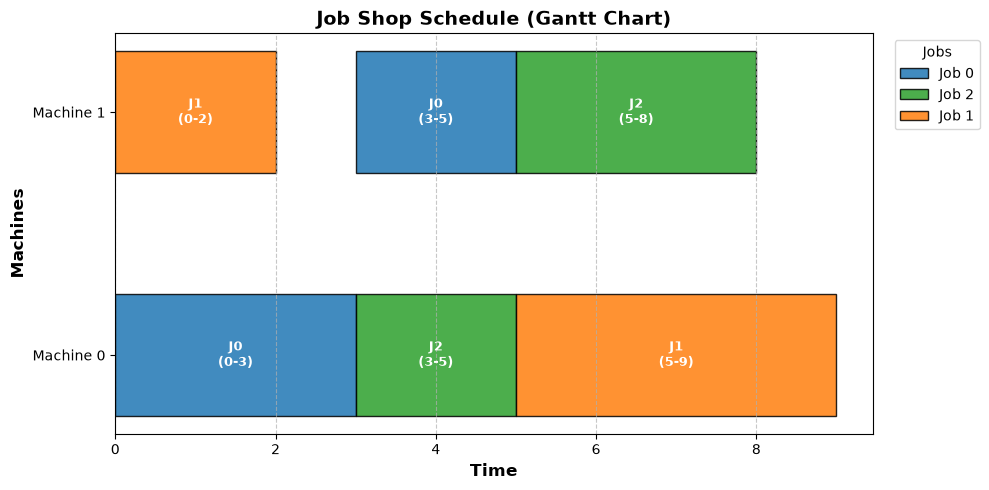

In [15]:
schedule1 = experiment.results['example1'][0].schedule
plot_jssp_schedule(schedule1)

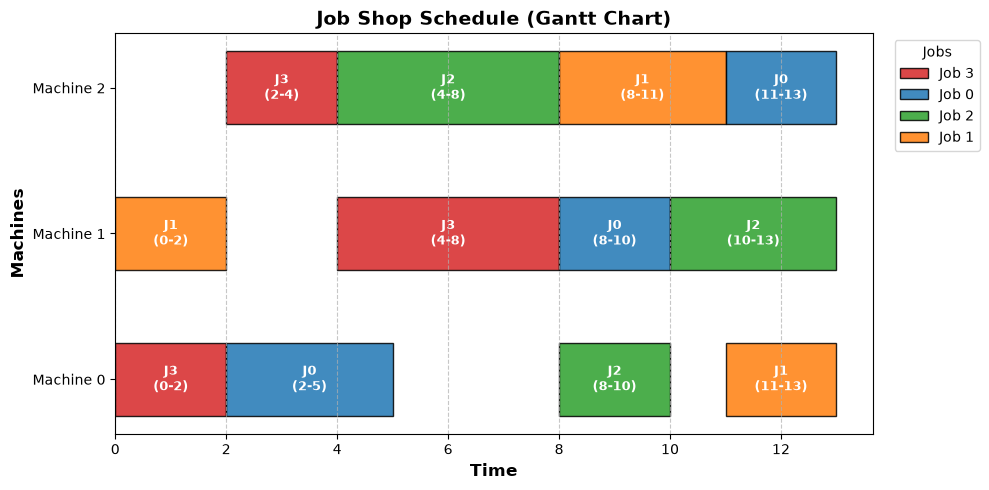

In [16]:
schedule2 = experiment.results['example2'][0].schedule
plot_jssp_schedule(schedule2)

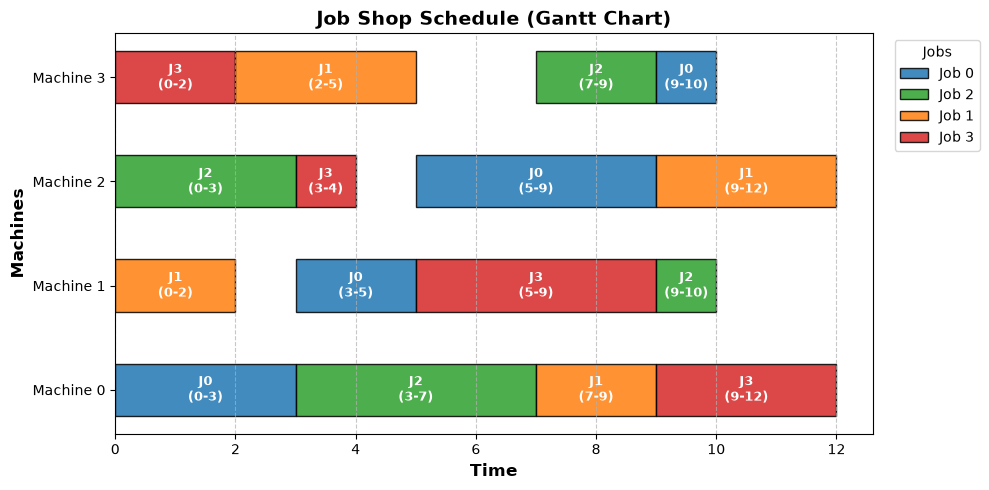

In [17]:
schedule3 = experiment.results['example3'][0].schedule
plot_jssp_schedule(schedule3)

In [18]:
# benchmark = Benchmark(
#     config_path = path_experiment_condig,
#     algorithms = [DFSSolver]
# )
# benchmark.run_benchmarks()

## A*

In [19]:
from functools import partial
from jssp.solvers.astar import AStarSolver

experiments = {}
for heuristic in ('h1', 'h2'):
    experiment = Experiment(config_path, partial(AStarSolver, heuristic=heuristic))
    experiment.run_experiment()
    experiments[heuristic] = experiment
    for instance_name, results in experiment.results.items():
        result = results[0]
        print(f'{heuristic}, {instance_name}: makespan={result.makespan}, runtime={result.runtime:.6f}s')

Running Experiments:   0%|          | 0/30 [00:00<?, ?it/s]

Running Experiments: 100%|██████████| 30/30 [00:00<00:00, 145.26it/s]


h1, example1: makespan=9, runtime=0.000443s
h1, example2: makespan=13, runtime=0.009186s
h1, example3: makespan=12, runtime=0.007423s


Running Experiments: 100%|██████████| 30/30 [00:00<00:00, 483.86it/s]

h2, example1: makespan=9, runtime=0.000472s
h2, example2: makespan=13, runtime=0.003281s
h2, example3: makespan=12, runtime=0.002408s


A* with h1


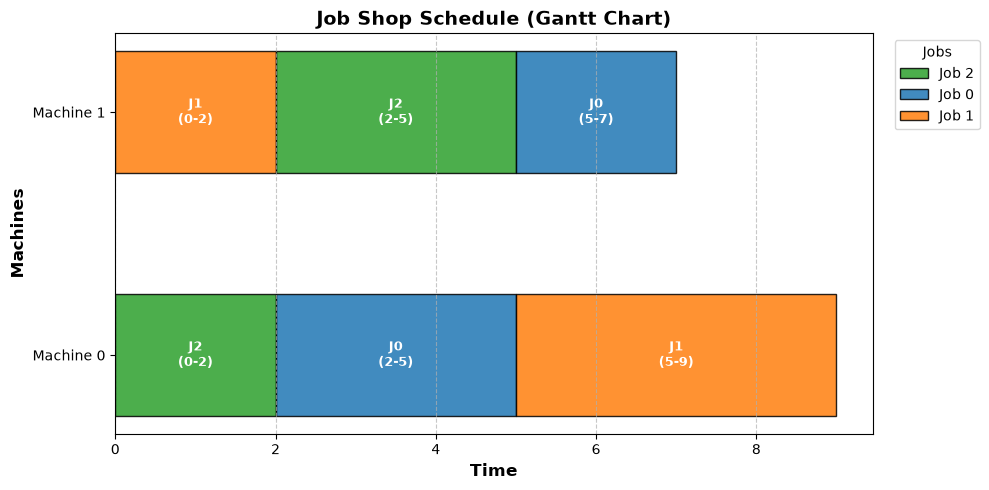

A* with h2


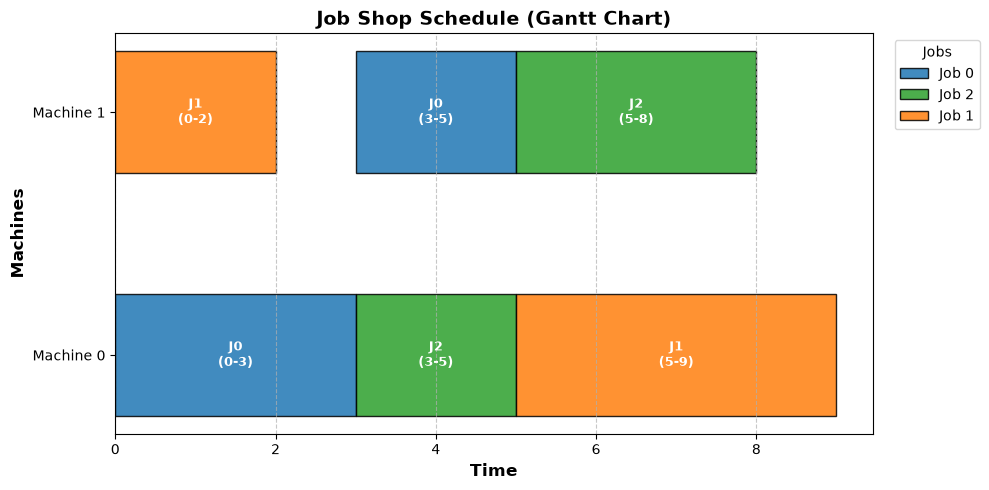

In [20]:
for heuristic, experiment in experiments.items():
    print(f'A* with {heuristic}')
    plot_jssp_schedule(experiment.results['example1'][0].schedule)

A* with h1


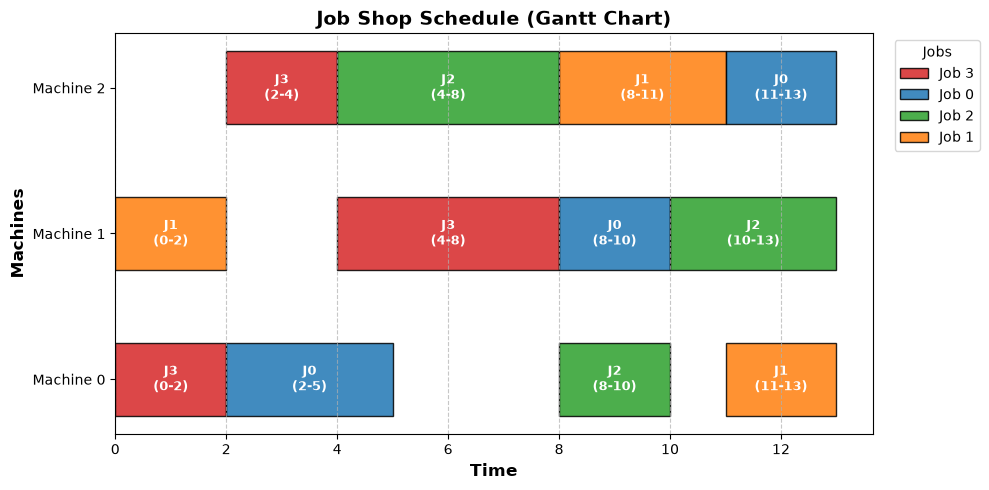

A* with h2


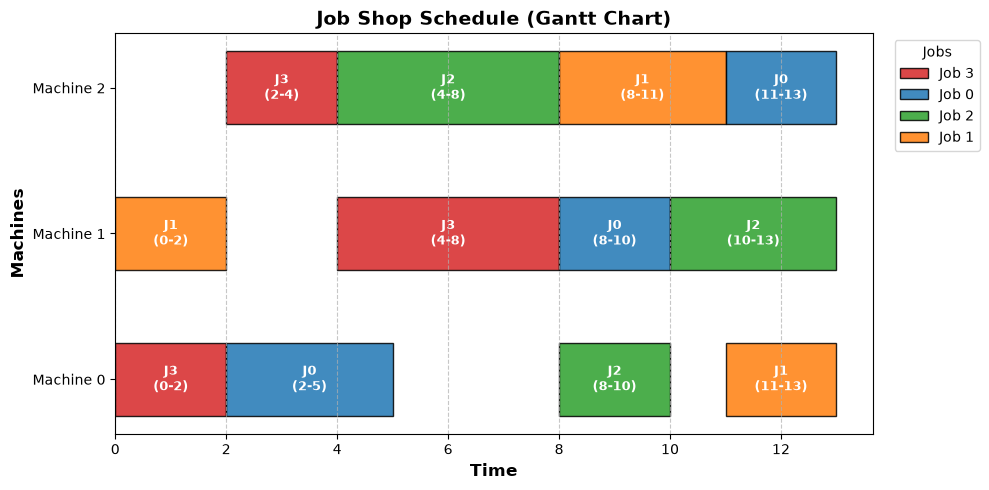

In [21]:
for heuristic, experiment in experiments.items():
    print(f'A* with {heuristic}')
    plot_jssp_schedule(experiment.results['example2'][0].schedule)

A* with h1


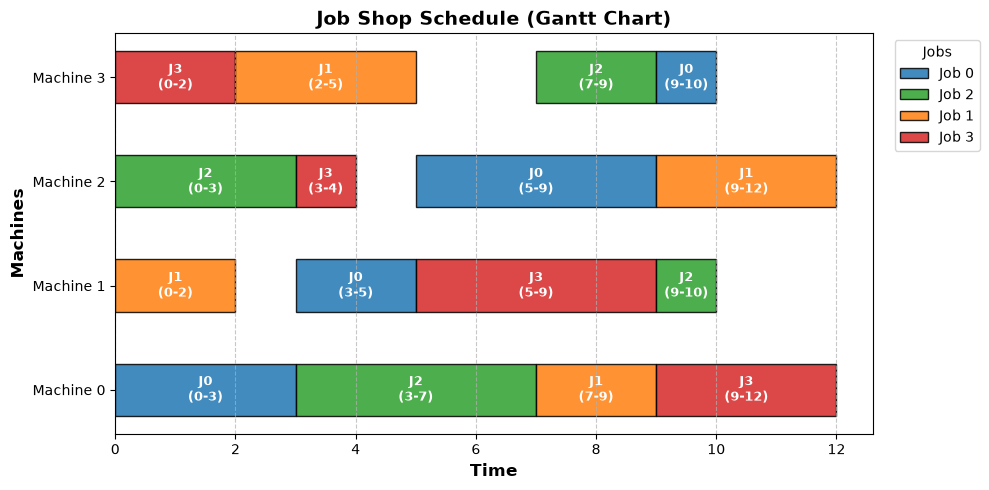

A* with h2


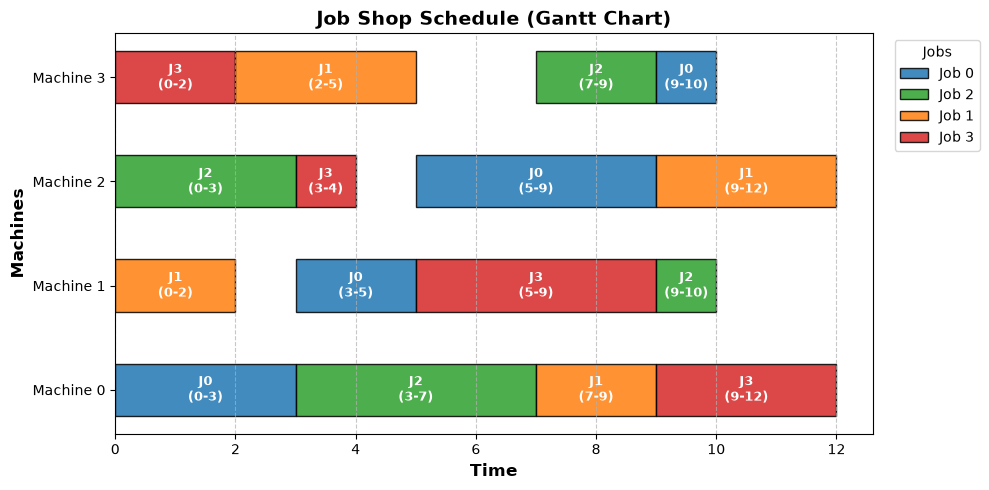

In [22]:
for heuristic, experiment in experiments.items():
    print(f'A* with {heuristic}')
    plot_jssp_schedule(experiment.results['example3'][0].schedule)